# Previsão de Vendas de Sorvete por Temperatura

Este projeto implementa um modelo de **Regressão Linear** para prever as vendas de sorvete (em milhares) com base na temperatura ambiente (ºC).

## 📌 Visão Geral

O objetivo é analisar a relação entre a temperatura e a quantidade de sorvetes vendidos, criando um modelo preditivo simples e eficaz para auxiliar na estimativa de demanda.

## 🛠️ Tecnologias e Bibliotecas Utilizadas
- **Python 3**
- **Pandas**: Para leitura e manipulação da base de dados (`Sorvete.xlsx`).
- **Matplotlib**: Para visualização de dados (gráficos de dispersão e linha de regressão).
- **Scikit-Learn**: Para divisão de dados de treino/teste, treinamento do modelo de Regressão Linear e avaliação de métricas.

## 📊 Resultados do Modelo
Após o treinamento, o modelo foi avaliado com as seguintes métricas:
- **R² (Coeficiente de Determinação)**: ~0.959 (indicando que aproximadamente 95,9% da variação nas vendas é explicada pela temperatura).
- **Erro Absoluto Médio (MAE)**: ~7.68 (unidades de vendas em milhares).
- **Erro Médio Quadrático (MSE)**: ~101.65.

Prevendo vendas de sorvetes com base na temperatura

In [ ]:
#Importando bibliotecas necessárias
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split #treino e teste
from sklearn.linear_model import LinearRegression ##regressão linear
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score #metricas de validação do modelo

# Importando a base de dados
DATA_BASE = pd.read_excel("Sorvete.xlsx")
DATA_BASE.head()

,Temperatura,Vendas_Sorvetes
0,26,268.125258
1,39,403.562400
2,34,339.279899
3,30,310.035329
4,27,273.616360


Que tal um gráfico para visualizar melhor esses dados de vendas em relação à temperatura? Vamos plotar um gráfico de scatter.

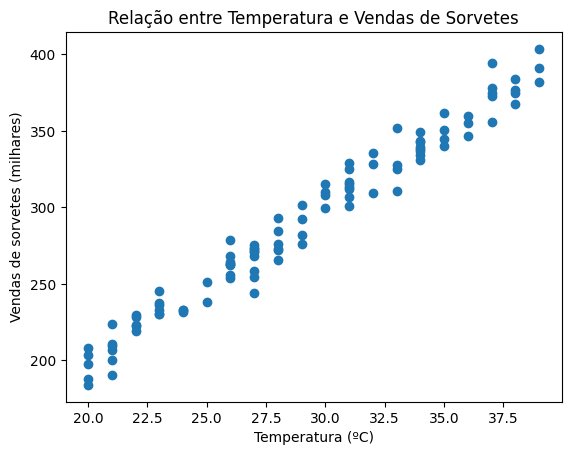

In [ ]:
#Visualizando os dados
plt.scatter(DATA_BASE["Temperatura"], DATA_BASE["Vendas_Sorvetes"]) #Gráfico de dispersão
plt.xlabel("Temperatura (ºC)")
plt.ylabel("Vendas de sorvetes (milhares)")
plt.title("Relação entre Temperatura e Vendas de Sorvetes")
plt.show()

In [ ]:
DATA_BASE.corr()

,Temperatura,Vendas_Sorvetes
Temperatura,1.000000,0.985589
Vendas_Sorvetes,0.985589,1.000000


CRIANDO O MODELO DE REGRESSÃO

In [ ]:
# Dividindo os dados em conjuntos de treinamento e teste
x = DATA_BASE[["Temperatura"]] #Recurso (variável independente)
y = DATA_BASE["Vendas_Sorvetes"] # Rótulo (variável dependente)

X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [ ]:
# Criando e treinando o modelo de regressão linear
modelo = LinearRegression()
modelo.fit(X_train, y_train) # treinando o modelo

# Fazendo previsões no conjunto de teste
previsoes = modelo.predict(X_test)

Avaliando os resultados

Erro Médio Quadrático: {101.64524989805876}
Erro Absoluto Médio: {7.6809927436910055}
R² (Coeficiente de Determinação): {0.9594169633031285}


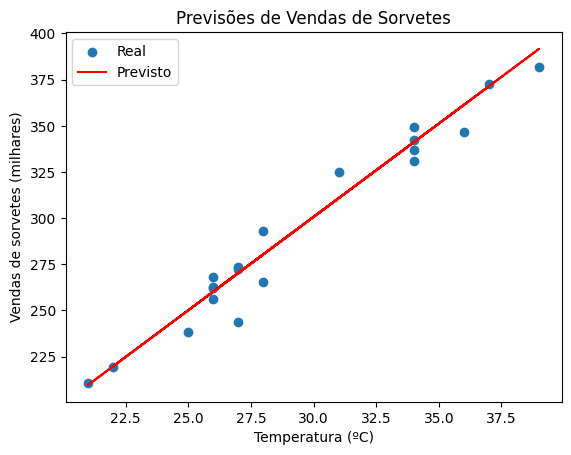

In [ ]:
# Avaliando o desempenho do modelo
erro_medio_quadratico = mean_squared_error(y_test, previsoes)
erro_absoluto_medio = mean_absolute_error(y_test, previsoes)
r_quadrado = r2_score(y_test, previsoes)

print(f"Erro Médio Quadrático:", {erro_medio_quadratico})
print(f"Erro Absoluto Médio:", {erro_absoluto_medio})
print(f"R² (Coeficiente de Determinação):", {r_quadrado})

# Visualizando as previsões
plt.scatter(X_test, y_test, label="Real")
plt.plot(X_test, previsoes, color="red", label="Previsto")
plt.xlabel("Temperatura (ºC)")
plt.ylabel("Vendas de sorvetes (milhares)")
plt.title("Previsões de Vendas de Sorvetes")
plt.legend()
plt.show()